# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

**Completed lab solution.** Original instructions: [NLP_Lab10](https://github.com/MohammedMosuily/NLP_Lab10).

    Run the cells from top to bottom. Results below were generated by executing this notebook. The `dataset` folder contains the original data needed by this lab. Missing Python packages are installed by the setup cell; pretrained model downloads need internet on their first run. Random seeds are fixed where supported.

In [1]:
# Install only missing dependencies into the active Jupyter Python environment.
import importlib.util, subprocess, sys, os, random
from pathlib import Path
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn', 'nltk': 'nltk', 'tensorflow': 'tensorflow-cpu'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['USE_TF'] = '0'  # Transformers examples use PyTorch.
os.environ['USE_FLAX'] = '0'
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML
random.seed(42)
np.random.seed(42)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 10)
DATA = Path('dataset')
assert DATA.exists() or 10 in (7, 8, 9), 'Open this notebook from its Lab folder.'

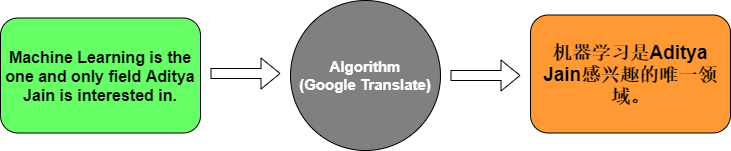

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

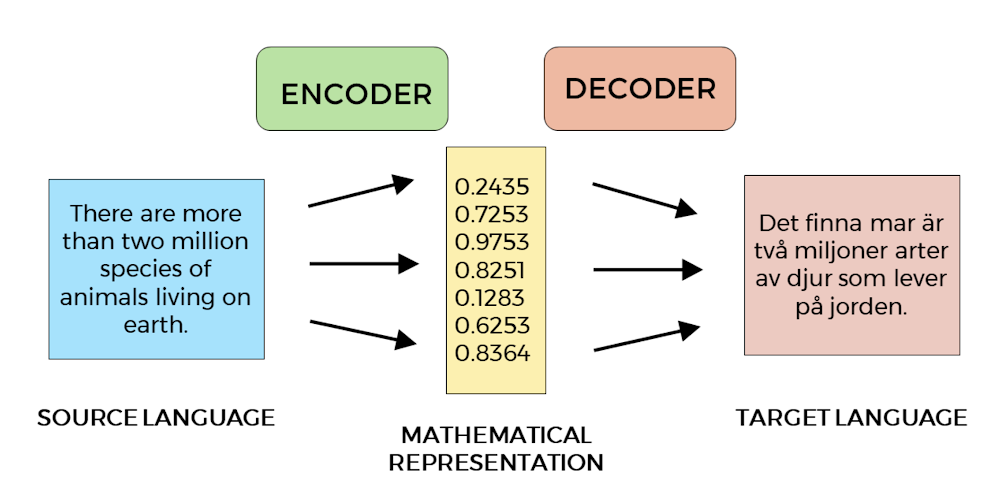


In [2]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
print('TensorFlow:',tf.__version__)

TensorFlow: 2.21.0


In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

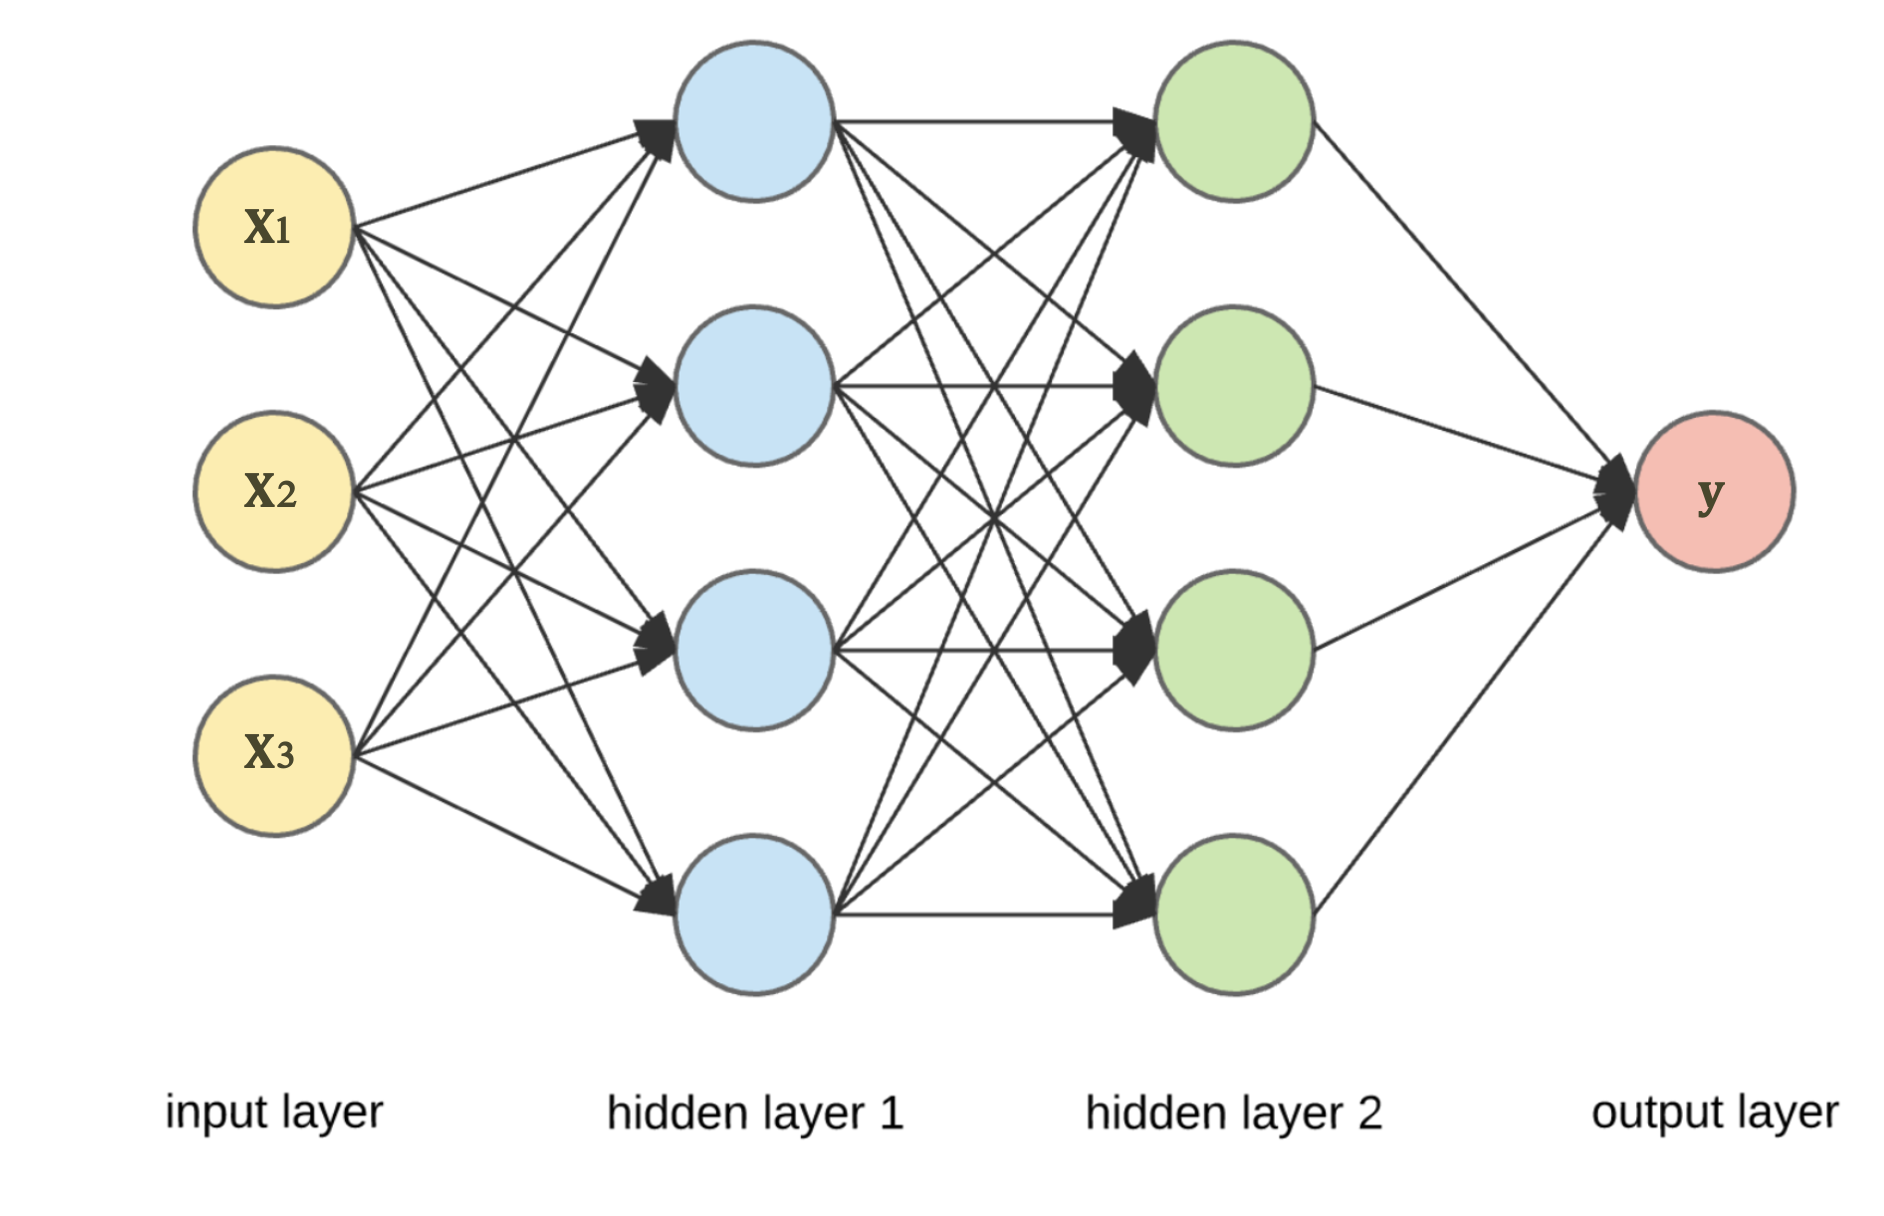

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history_toy = model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, verbose=0)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')
print('Final training loss:',round(history_toy.history['loss'][-1],4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step - accuracy: 0.5714 - loss: 1.7287

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.5714 - loss: 1.7287


Test Accuracy: 0.5714285969734192
Final training loss: 0.737


In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step


Input: How are you?
Translation: comment ça va


**Demonstration limit:** The three-pair example leaves only two training examples and one test example. Its token accuracy includes padding and is not evidence of a useful translator. Task 2 below uses a larger real parallel corpus, independent train/validation/test source sentences, explicit start/end tokens, and a padding-excluded test metric.

________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


In [9]:
# Answers are in the following Markdown cell.
print('See the model-layer explanations below.')

See the model-layer explanations below.


### Task 1 answers
1. The Embedding layer looks up a learned dense vector for each integer word ID. Related words can acquire similar vector representations.
2. The encoder LSTM reads the source sequence and summarizes it in its final hidden and cell states (or the fixed context vector in the simple demonstration).
3. The decoder LSTM uses the source representation and target history to generate target-language tokens in sequence.
4. Softmax converts output scores into a probability distribution over the French vocabulary, allowing a next-token prediction.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

Real corpus pairs used: 12000
Train/validation/test: 8670 1530 1800


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_prefix       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 8, 64)     │    281,664 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 8)         │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 64)  │    398,272 │ french_prefix[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder (LSTM)      │ [(None, 96),      │     61,824 │ embedding_1[0][0… │
│                     │ (None, 96),       │            │ not_equal[0][0]   │
│                     │ (None, 96)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder (LSTM)      │ [(None, None,     │     61,824 │ embedding_2[0][0… │
│                     │ 96), (None, 96),  │            │ encoder[0][1],    │
│                     │ (None, 96)]       │            │ encoder[0][2]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │    603,631 │ decoder[0][0]     │
│                     │ 6223)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,407,215 (5.37 MB)

 Trainable params: 1,407,215 (5.37 MB)

 Non-trainable params: 0 (0.00 B)

Epochs completed: 15
Best validation loss: 4.534710884094238


Held-out teacher-forced token accuracy (padding excluded): 0.32875942866313596


Free-generation BLEU on first 200 held-out pairs (0-1): 0.02201957371980567


,English,Reference,Generated
0,show me the way please,veuillez me montrer le chemin je vous prie,ils ont ils sont
1,have a drink while you're waiting,prenez un verre en attendant,les gens sont pas de la enfants
2,mother went shopping with my brother,mère est partie faire des courses avec mon frère,les gens sont plus de la maison
3,may i have something hot to drink,pourrais je avoir quelque chose de chaud à boire,je pense que je ne suis pas à la maison
4,i was arrested for aiding in his escape,j'ai été arrêté pour l'avoir aidé dans sa fuite,j'ai un peu de la maison que je le plaît
5,please leave me alone,s'il vous plaît laissez moi tranquille,ils ont ils sont
6,you said you wanted a family,tu as dit que tu voulais une famille,tu as pas de faire un peu
7,i've already finished reading this book,j ai déjà fini de lire ce livre,j'ai un peu de temps que tom


E-commerce examples:
the price is good -> le monde est très en
i like this product -> j'adore les ville
thank you very much -> puis je veux


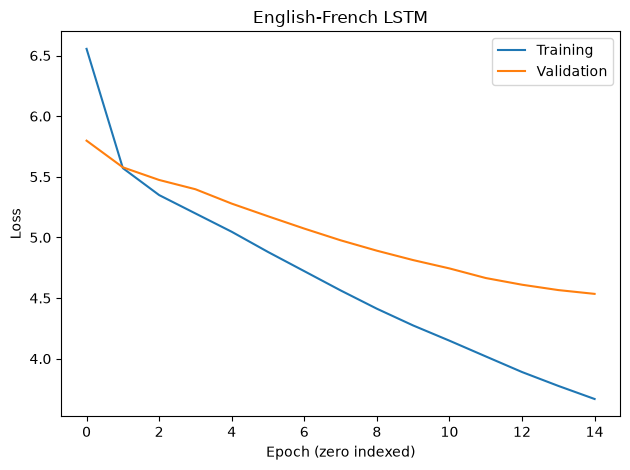

In [10]:
import re, unicodedata
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import matplotlib.pyplot as plt
parallel=pd.read_csv(DATA / 'eng_-french.csv').dropna()
parallel.columns=['english','french']
def normalize_sentence(text):
    text=unicodedata.normalize('NFKC',str(text)).lower()
    text=re.sub(r"[^\w\s']",' ',text,flags=re.UNICODE)
    return re.sub(r'\s+',' ',text).strip()
parallel['english']=parallel.english.map(normalize_sentence)
parallel['french']=parallel.french.map(normalize_sentence)
parallel=parallel[(parallel.english.str.split().str.len().between(2,8)) &
                  (parallel.french.str.split().str.len().between(2,10))]
parallel=parallel.drop_duplicates('english')
# A seeded 12,000-pair subset keeps this instructional LSTM practical on a CPU.
parallel=parallel.sample(n=min(12000,len(parallel)),random_state=42).reset_index(drop=True)
train_pairs,test_pairs=train_test_split(parallel,test_size=0.15,random_state=42)
train_pairs,val_pairs=train_test_split(train_pairs,test_size=0.15,random_state=42)
src_tok=Tokenizer(oov_token='oov',filters='')
tgt_tok=Tokenizer(oov_token='oov',filters='')
src_tok.fit_on_texts(train_pairs.english)
tgt_tok.fit_on_texts('startseq '+train_pairs.french+' endseq')
SRC_LEN=8
TGT_LEN=11  # At most 10 French tokens plus endseq (decoder target).
def encode_pairs(frame):
    src=pad_sequences(src_tok.texts_to_sequences(frame.english),maxlen=SRC_LEN,padding='post')
    dec_in=pad_sequences(tgt_tok.texts_to_sequences('startseq '+frame.french),maxlen=TGT_LEN,padding='post')
    dec_out=pad_sequences(tgt_tok.texts_to_sequences(frame.french+' endseq'),maxlen=TGT_LEN,padding='post')
    return src,dec_in,dec_out
src_train,di_train,do_train=encode_pairs(train_pairs)
src_val,di_val,do_val=encode_pairs(val_pairs)
src_test,di_test,do_test=encode_pairs(test_pairs)
print('Real corpus pairs used:',len(parallel))
print('Train/validation/test:',len(train_pairs),len(val_pairs),len(test_pairs))

tf.keras.utils.set_random_seed(42)
src_input=tf.keras.Input(shape=(SRC_LEN,),dtype='int32',name='english')
src_emb=tf.keras.layers.Embedding(len(src_tok.word_index)+1,64,mask_zero=True)(src_input)
_,state_h,state_c=tf.keras.layers.LSTM(96,return_state=True,name='encoder')(src_emb)
decoder_input=tf.keras.Input(shape=(None,),dtype='int32',name='french_prefix')
target_embedding=tf.keras.layers.Embedding(len(tgt_tok.word_index)+1,64,mask_zero=True)
decoder_lstm=tf.keras.layers.LSTM(96,return_sequences=True,return_state=True,name='decoder')
decoder_output,_,_=decoder_lstm(target_embedding(decoder_input),initial_state=[state_h,state_c])
projection=tf.keras.layers.Dense(len(tgt_tok.word_index)+1,activation='softmax')
translation_model=tf.keras.Model([src_input,decoder_input],projection(decoder_output))
translation_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy')
translation_model.summary()
history=translation_model.fit([src_train,di_train],do_train,
    sample_weight=(do_train!=0).astype('float32'),batch_size=64,epochs=15,
    validation_data=([src_val,di_val],do_val,(do_val!=0).astype('float32')),
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)],verbose=0)
print('Epochs completed:',len(history.history['loss']))
print('Best validation loss:',min(history.history['val_loss']))

# Evaluate nonpadding tokens under teacher forcing, separately from free generation.
test_probs=translation_model.predict([src_test,di_test],batch_size=32,verbose=0)
mask=do_test!=0
print('Held-out teacher-forced token accuracy (padding excluded):',
      float((test_probs.argmax(-1)[mask]==do_test[mask]).mean()))
del test_probs
encoder_model=tf.keras.Model(src_input,[state_h,state_c])
step_token=tf.keras.Input(shape=(1,),dtype='int32')
step_h=tf.keras.Input(shape=(96,));step_c=tf.keras.Input(shape=(96,))
step_out,next_h,next_c=decoder_lstm(target_embedding(step_token),initial_state=[step_h,step_c])
decoder_model=tf.keras.Model([step_token,step_h,step_c],[projection(step_out),next_h,next_c])
def translate_batch(sentences):
    source=pad_sequences(src_tok.texts_to_sequences([normalize_sentence(s) for s in sentences]),
                         maxlen=SRC_LEN,padding='post')
    h,c=encoder_model(source,training=False)
    token=np.full((len(sentences),1),tgt_tok.word_index['startseq'],dtype=np.int32)
    generated=[[] for _ in sentences];finished=np.zeros(len(sentences),dtype=bool)
    for _ in range(TGT_LEN):
        probs,h,c=decoder_model([tf.convert_to_tensor(token),h,c],training=False)
        next_ids=np.argmax(probs.numpy()[:,0,:],axis=-1)
        for j,word_id in enumerate(next_ids):
            word=tgt_tok.index_word.get(int(word_id),'')
            if word in ('endseq',''): finished[j]=True
            if not finished[j] and word!='startseq': generated[j].append(word)
        token=next_ids[:,None].astype(np.int32)
        if finished.all():break
    return [' '.join(words) for words in generated]
bleu_frame=test_pairs.head(200)
hypotheses=translate_batch(bleu_frame.english.tolist())
bleu=corpus_bleu([[s.split()] for s in bleu_frame.french],
    [s.split() for s in hypotheses],smoothing_function=SmoothingFunction().method1)
print('Free-generation BLEU on first 200 held-out pairs (0-1):',bleu)
display(pd.DataFrame({'English':bleu_frame.english.tolist()[:8],
                     'Reference':bleu_frame.french.tolist()[:8],
                     'Generated':hypotheses[:8]}))
print('E-commerce examples:')
examples=['the price is good','i like this product','thank you very much']
for sentence,translation in zip(examples,translate_batch(examples)):
    print(sentence,'->',translation)
plt.plot(history.history['loss'],label='Training')
plt.plot(history.history['val_loss'],label='Validation')
plt.xlabel('Epoch (zero indexed)');plt.ylabel('Loss');plt.title('English-French LSTM')
plt.legend();plt.tight_layout();plt.show()

### Task 2 conclusion
This is a trained encoder-decoder LSTM using the specified English-French dataset. Tokenizers are fitted only on training pairs, identical normalized English inputs cannot cross splits, and padding is excluded from the reported token metric. Teacher-forced accuracy is easier than free generation, so an additional generated-output BLEU score and reference translations are shown. The short, general-domain training subset and small model are educational; weak translations or unknown words are expected for e-commerce text. A production system would require product-domain parallel data, stronger pretrained models and human review.